# Delivery Ops Analytics — what makes on-demand deliveries late?

**Question:** In an on-demand delivery network, which operational factors push orders past a 30-minute promise — and what should ops teams change first?

**Data:** 45,593 food-delivery orders across 22 Indian cities and 1,320 delivery partners (Feb–Apr 2022). Public dataset from Kaggle ([Food Delivery Dataset, Gaurav Malik](https://www.kaggle.com/datasets/gauravmalik26/food-delivery-dataset)).

**Definition used throughout:** an order is **late** if it took **more than 30 minutes**.

**Workflow:** raw CSV → `src/clean.py` (cleaning + feature engineering) → SQLite → SQL questions in `sql/analysis.sql` → charts and findings below.

In [1]:
import sqlite3, sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from chart_style import apply_style, hbar, subtitle, ACCENT, MUTED, TEXT_2

apply_style()
CHARTS = ROOT / "outputs" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(ROOT / "data" / "processed" / "deliveries.db")
q = lambda sql: pd.read_sql(sql, con)
df = q("SELECT * FROM deliveries")
df.shape

(45593, 21)

## 1. Data quality check
The raw export had whitespace padding, the literal text `NaN` instead of blanks, times stored as `(min) 24`, negative coordinates and a few impossible ages/ratings. `clean.py` fixes these. What's still missing after cleaning:

In [2]:
missing = df.isna().sum()
(missing[missing > 0] / len(df) * 100).round(1).rename("% missing").to_frame()

,% missing
area_type,2.6
partner_age,4.1
partner_rating,4.3
order_hour,3.8
time_slot,3.8
pickup_wait_min,3.8
weather,1.4
traffic,1.3
multiple_deliveries,2.2
festival,0.5


All gaps are under 8% and spread across columns, so each question below simply ignores rows missing that one field instead of dropping whole orders.

## 2. Headline numbers

In [3]:
kpi = q('''
SELECT COUNT(*) AS orders,
       COUNT(DISTINCT partner_id) AS partners,
       COUNT(DISTINCT city_name) AS cities,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries
''')
kpi

,orders,partners,cities,avg_delivery_min,late_pct
0,45593,1320,22,26.3,29.8


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


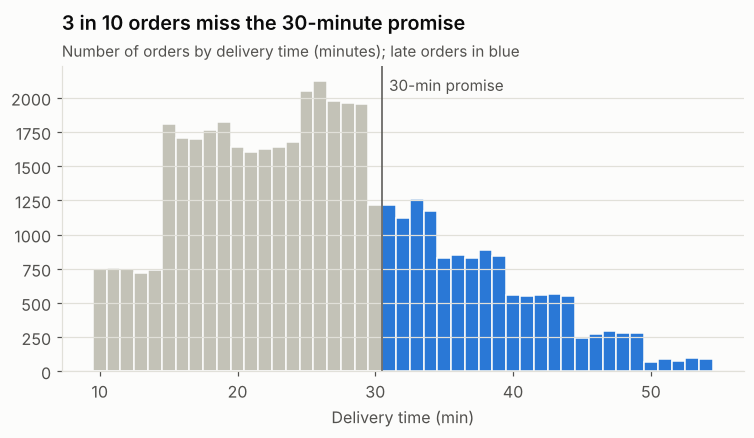

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = [b + 0.5 for b in range(9, 55)]  # one bar per minute
on_time = df.loc[df["delivery_min"] <= 30, "delivery_min"]
late = df.loc[df["delivery_min"] > 30, "delivery_min"]
ax.hist(on_time, bins=bins, color=MUTED, edgecolor="#fcfcfb", linewidth=1)
ax.hist(late, bins=bins, color=ACCENT, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(30.5, color=TEXT_2, linewidth=1)
ax.text(31, ax.get_ylim()[1] * 0.92, "30-min promise", color=TEXT_2, fontsize=10)
ax.set_title("3 in 10 orders miss the 30-minute promise", pad=24)
subtitle(ax, "Number of orders by delivery time (minutes); late orders in blue")
ax.set_xlabel("Delivery time (min)")
ax.grid(axis="x", visible=False)
fig.savefig(CHARTS / "01_delivery_time_distribution.png")
plt.show()

## 3. Traffic and the dinner rush

In [5]:
traffic = q('''
SELECT traffic, COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE traffic IS NOT NULL
GROUP BY traffic
ORDER BY CASE traffic WHEN 'Low' THEN 1 WHEN 'Medium' THEN 2 WHEN 'High' THEN 3 ELSE 4 END
''')
traffic

,traffic,orders,avg_delivery_min,late_pct
0,Low,15477,21.3,7.9
1,Medium,10947,26.7,32.5
2,High,4425,27.2,33.6
3,Jam,14143,31.2,50.6


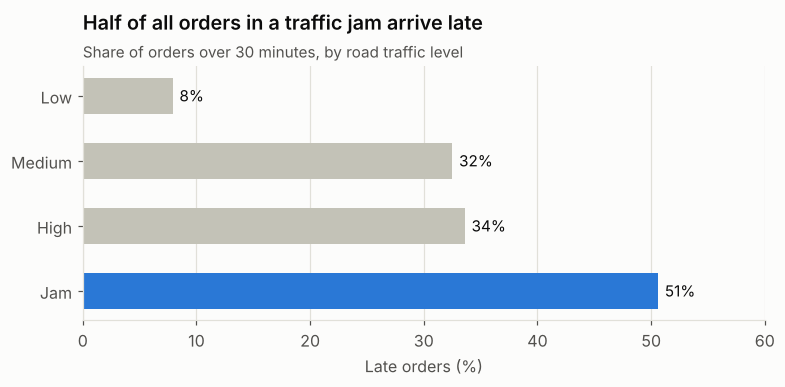

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
hbar(ax, traffic["traffic"], traffic["late_pct"], highlight=["Jam"], xlabel="Late orders (%)", xmax=60)
ax.set_title("Half of all orders in a traffic jam arrive late", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by road traffic level")
fig.savefig(CHARTS / "02_late_by_traffic.png")
plt.show()

In [7]:
slots = q('''
SELECT time_slot, COUNT(*) AS orders,
       ROUND(100.0 * AVG(traffic = 'Jam'), 1) AS jam_pct,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE time_slot IS NOT NULL
GROUP BY time_slot
''')
order = ["Breakfast (6-11)", "Lunch (11-15)", "Evening snack (15-18)", "Dinner (18-22)", "Late night (22-6)"]
slots = slots.set_index("time_slot").loc[order].reset_index()
slots["share_of_orders_pct"] = (slots["orders"] / slots["orders"].sum() * 100).round(1)
slots

,time_slot,orders,jam_pct,avg_delivery_min,late_pct,share_of_orders_pct
0,Breakfast (6-11),5756,0.0,19.5,2.2,13.1
1,Lunch (11-15),4429,0.0,26.9,32.0,10.1
2,Evening snack (15-18),5860,0.0,26.2,30.5,13.4
3,Dinner (18-22),18300,73.2,30.1,46.4,41.7
4,Late night (22-6),9517,4.2,22.8,13.3,21.7


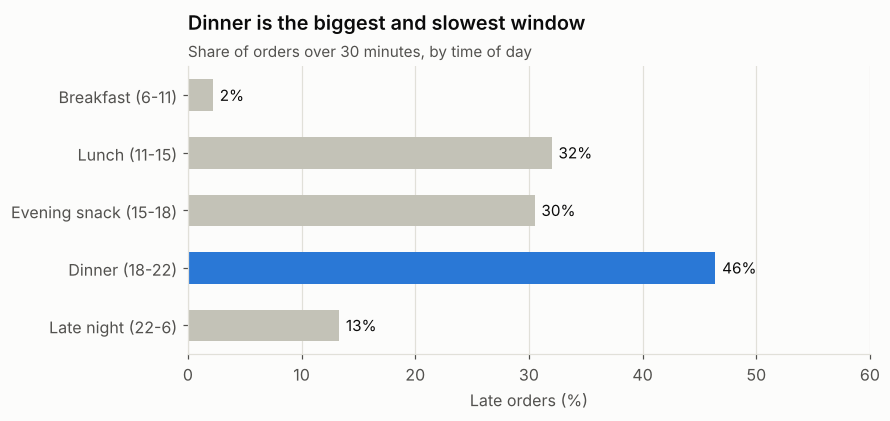

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
hbar(ax, slots["time_slot"], slots["late_pct"], highlight=["Dinner (18-22)"], xlabel="Late orders (%)", xmax=60)
ax.set_title("Dinner is the biggest and slowest window", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by time of day")
fig.savefig(CHARTS / "03_late_by_time_slot.png")
plt.show()

**Finding:** Dinner (6–10 pm) brings about 42% of all orders, and nearly three in four of them hit jammed roads. Traffic is the single biggest driver: late rate climbs from about 8% on clear roads to about 51% in a jam.

## 4. Stacking orders on one partner

In [9]:
stack = q('''
SELECT CAST(multiple_deliveries AS INT) AS extra_orders_carried, COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE multiple_deliveries IS NOT NULL
GROUP BY extra_orders_carried ORDER BY extra_orders_carried
''')
stack

,extra_orders_carried,orders,avg_delivery_min,late_pct
0,0,14095,22.9,18.1
1,1,28159,26.9,30.3
2,2,1985,40.5,100.0
3,3,361,47.8,100.0


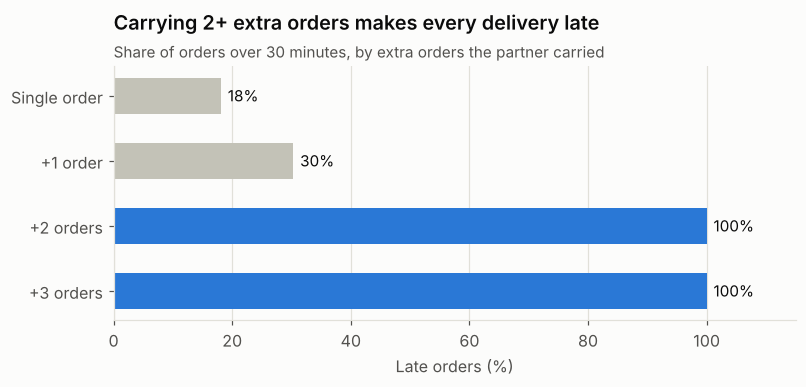

In [10]:
labels = ["Single order", "+1 order", "+2 orders", "+3 orders"]
fig, ax = plt.subplots(figsize=(8, 3))
hbar(ax, labels, stack["late_pct"], highlight=["+2 orders", "+3 orders"], xlabel="Late orders (%)", xmax=115)
ax.set_title("Carrying 2+ extra orders makes every delivery late", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by extra orders the partner carried")
fig.savefig(CHARTS / "04_late_by_stacked_orders.png")
plt.show()

**Finding:** Batching one extra order is manageable (30% late). Two or more extra orders pushes the late rate to 100% and average time past 40 minutes — a clear rule: cap stacking at one extra order.

## 5. Distance from pickup to customer

In [11]:
dist = q('''
SELECT CASE WHEN distance_km < 5 THEN 'Under 5 km' WHEN distance_km < 10 THEN '5-10 km'
            WHEN distance_km < 15 THEN '10-15 km' ELSE '15+ km' END AS distance_band,
       COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE distance_km IS NOT NULL
GROUP BY distance_band
''').set_index("distance_band").loc[["Under 5 km", "5-10 km", "10-15 km", "15+ km"]].reset_index()
dist

,distance_band,orders,avg_delivery_min,late_pct
0,Under 5 km,11303,22.2,12.4
1,5-10 km,11307,24.4,21.1
2,10-15 km,11293,29.8,45.5
3,15+ km,8050,29.9,45.1


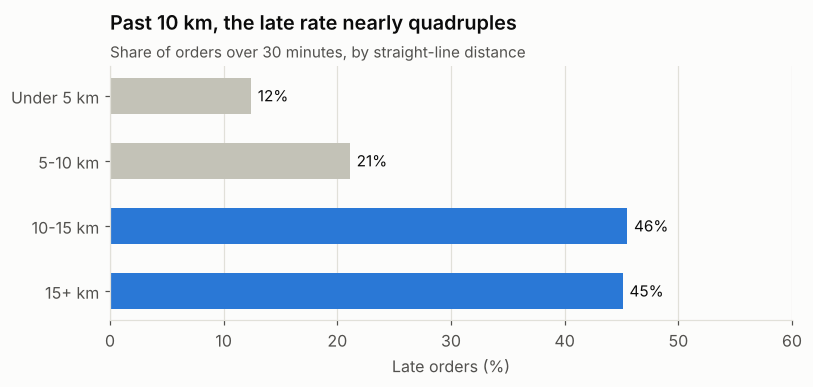

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
hbar(ax, dist["distance_band"], dist["late_pct"], highlight=["10-15 km", "15+ km"], xlabel="Late orders (%)", xmax=60)
ax.set_title("Past 10 km, the late rate nearly quadruples", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by straight-line distance")
fig.savefig(CHARTS / "05_late_by_distance.png")
plt.show()

**Finding:** Orders under 5 km are late 12% of the time; beyond 10 km it's about 45%. Keeping each partner's service radius tight (a micro-market) protects the promise more than anything a partner can do on the road.

## 6. Weather and festival days

In [13]:
weather = q('''
SELECT weather, COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE weather IS NOT NULL
GROUP BY weather ORDER BY late_pct DESC
''')
weather

,weather,orders,avg_delivery_min,late_pct
0,Fog,7654,28.9,43.8
1,Cloudy,7536,28.9,43.8
2,Windy,7422,26.1,26.6
3,Sandstorms,7495,25.9,26.0
4,Stormy,7586,25.9,25.5
5,Sunny,7284,21.9,12.5


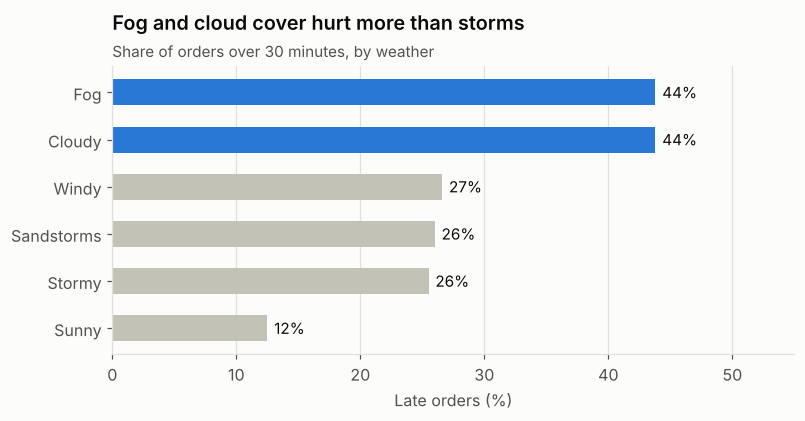

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.4))
hbar(ax, weather["weather"], weather["late_pct"], highlight=["Fog", "Cloudy"], xlabel="Late orders (%)", xmax=55)
ax.set_title("Fog and cloud cover hurt more than storms", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by weather")
fig.savefig(CHARTS / "06_late_by_weather.png")
plt.show()

In [15]:
q('''
SELECT festival, COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE festival IS NOT NULL GROUP BY festival
''')

,festival,orders,avg_delivery_min,late_pct
0,No,44469,26.0,28.6
1,Yes,896,45.5,100.0


**Finding:** On festival days every single order (896 of 896) was late, averaging 45.5 minutes vs 26 on normal days. Festivals are predictable — this is a planning gap, fixable with surge staffing scheduled in advance.

## 7. Partner ratings

In [16]:
rating = q('''
SELECT CASE WHEN partner_rating < 4.0 THEN 'Below 4.0' WHEN partner_rating < 4.5 THEN '4.0-4.4'
            WHEN partner_rating < 4.8 THEN '4.5-4.7' ELSE '4.8-5.0' END AS rating_band,
       COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries WHERE partner_rating IS NOT NULL
GROUP BY rating_band
''').set_index("rating_band").loc[["Below 4.0", "4.0-4.4", "4.5-4.7", "4.8-5.0"]].reset_index()
rating

,rating_band,orders,avg_delivery_min,late_pct
0,Below 4.0,1367,36.8,97.7
1,4.0-4.4,6695,34.6,81.5
2,4.5-4.7,17385,24.2,16.4
3,4.8-5.0,18185,24.4,18.5


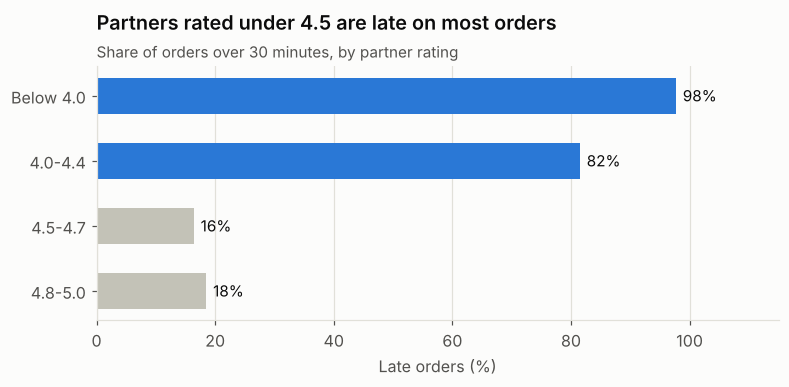

In [17]:
fig, ax = plt.subplots(figsize=(8, 3))
hbar(ax, rating["rating_band"], rating["late_pct"], highlight=["Below 4.0", "4.0-4.4"], xlabel="Late orders (%)", xmax=115)
ax.set_title("Partners rated under 4.5 are late on most orders", pad=24)
subtitle(ax, "Share of orders over 30 minutes, by partner rating")
fig.savefig(CHARTS / "07_late_by_rating.png")
plt.show()

**Finding:** Partners rated below 4.5 handle about 18% of orders but are late on 80%+ of them. This is a correlation, not proof — customers may rate *because* the order was late — but it makes the rating a cheap early-warning signal for who needs coaching or lighter loads.

## 8. Cities

In [18]:
city = q('''
SELECT city_name, COUNT(*) AS orders,
       ROUND(AVG(delivery_min), 1) AS avg_delivery_min,
       ROUND(100.0 * AVG(delivery_min > 30), 1) AS late_pct
FROM deliveries GROUP BY city_name ORDER BY late_pct DESC
''')
city.head(5)

,city_name,orders,avg_delivery_min,late_pct
0,Dehradun,737,26.7,33.0
1,Prayagraj,740,27.0,32.6
2,Jaipur,3443,26.7,31.9
3,Aurangabad,703,26.6,31.9
4,Bhopal,691,26.8,31.7


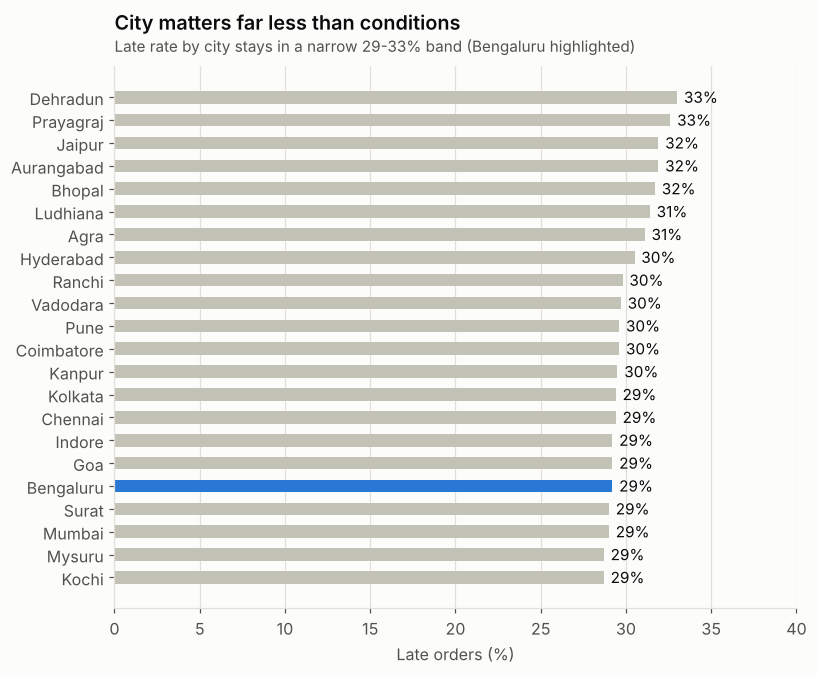

In [19]:
fig, ax = plt.subplots(figsize=(8, 6.4))
hbar(ax, city["city_name"], city["late_pct"], highlight=["Bengaluru"], xlabel="Late orders (%)", xmax=40)
ax.set_title("City matters far less than conditions", pad=24)
subtitle(ax, "Late rate by city stays in a narrow 29-33% band (Bengaluru highlighted)")
fig.savefig(CHARTS / "08_late_by_city.png")
plt.show()

**Finding:** The worst city (Dehradun, 33%) and the best (Kochi, 29%) are only 4 points apart, while traffic alone swings the late rate by 43 points. Fixes should target conditions (dinner, distance, stacking, festivals), not specific cities.

## 9. One surprise worth checking

In [20]:
df.pivot_table(index="vehicle_condition", columns="traffic", values="delivery_min", aggfunc="mean").round(1)

traffic,High,Jam,Low,Medium
vehicle_condition,,,,
0,31.5,36.3,23.9,30.5
1,25.2,28.7,19.8,24.7
2,25.0,28.7,20.0,24.9


Vehicles marked condition **0 (best)** are about 6 minutes *slower* than condition 1–2 at every traffic level, and they are all motorcycles. That's the opposite of what you'd expect, so it's flagged as a likely labelling issue to confirm with the data owner before acting on it.

## 10. Recommendations

| # | Problem found | What to do |
|---|---|---|
| 1 | Dinner (6–10 pm) = ~42% of orders, ~3 in 4 in jammed traffic | Add partners and pre-position them inside busy zones before 6 pm |
| 2 | 2+ stacked orders → 100% late | Cap batching at one extra order per partner |
| 3 | Orders over 10 km are late ~45% of the time | Tighten service radius; assign from the nearest micro-market |
| 4 | Festival days → every order late | Schedule surge staffing ahead of known festival dates |
| 5 | Partners rated < 4.5 are late on 80%+ of orders | Use rating as an early-warning flag for coaching and lighter loads |

**Limitations:** delivery time is the only outcome available (no cancellations or revenue), distance is straight-line rather than road distance, and the dataset covers just 8 weeks.